# 02 · Efficiency Analysis

Encoding latency and throughput per model/dataset, plus the
**accuracy-vs-latency trade-off** (merges `efficiency.csv` with
`retrieval_metrics.csv`).

Feed data in `findings_data/efficiency.csv`; the required columns are
`model, dataset, latency_mean_ms, latency_std_ms, throughput_clips_s`.

In [1]:
import research_utils as ru

eff = ru.load_findings("efficiency")
eff

,model,dataset,latency_mean_ms,latency_std_ms,throughput_clips_s
0,vljepa,ucf_crime,78.4,6.2,12.8
1,vljepa,rlvs,74.9,5.1,13.4
2,clip,ucf_crime,41.7,3.4,24.0
3,clip,rlvs,39.8,2.9,25.1


## Latency per clip (mean ± std)

[research] figure -> eff_latency_bars.png, eff_latency_bars.pdf


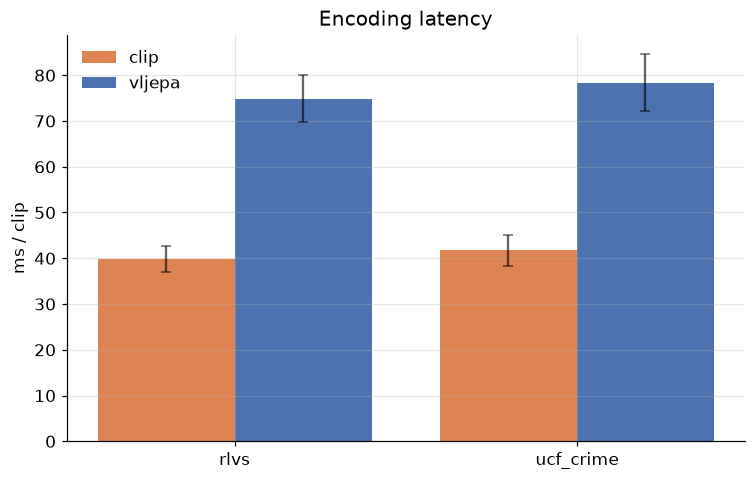

In [2]:
fig, ax = ru.plot_errorbar_bars(eff, value="latency_mean_ms", err="latency_std_ms",
                               group="dataset", hue="model",
                               ylabel="ms / clip",
                               title="Encoding latency",
                               save="eff_latency_bars")

In [3]:
ru.style_table(eff)

,model,dataset,latency_mean_ms,latency_std_ms,throughput_clips_s
0,vljepa,ucf_crime,78.400,6.200,12.800
1,vljepa,rlvs,74.900,5.100,13.400
2,clip,ucf_crime,41.700,3.400,24.000
3,clip,rlvs,39.800,2.900,25.100


## Throughput

[research] figure -> eff_throughput_bars.png, eff_throughput_bars.pdf


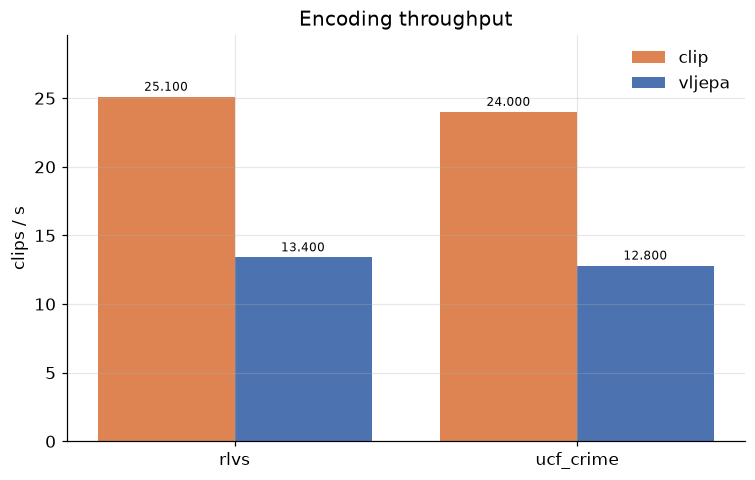

In [4]:
fig, ax = ru.plot_grouped_bars(eff, value="throughput_clips_s",
                              group="dataset", hue="model",
                              ylabel="clips / s",
                              title="Encoding throughput",
                              save="eff_throughput_bars")

## Accuracy vs latency trade-off

Each point is one (model, dataset). Upper-left = fast and accurate.

[research] figure -> eff_tradeoff_scatter.png, eff_tradeoff_scatter.pdf


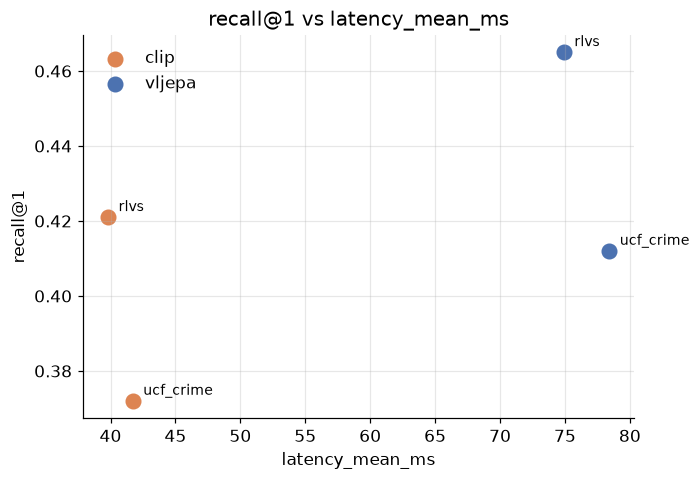

In [5]:
metrics = ru.load_findings(
    "retrieval_metrics",
    fallbacks=[ru.PIPELINE_RESULTS_DIR / "metrics" / "comparison_table.csv"],
)
fig, ax = ru.plot_scatter_tradeoff(metrics, eff, quality="recall@1",
                                  latency="latency_mean_ms",
                                  save="eff_tradeoff_scatter")

## Export

In [6]:
ru.export_table(eff, "eff_latency_throughput")

[research] table -> eff_latency_throughput.csv, eff_latency_throughput.tex


[WindowsPath('C:/Users/HPCLAB/Desktop/VLJEPA/capestone/implementation/research/outputs/eff_latency_throughput.csv'),
 WindowsPath('C:/Users/HPCLAB/Desktop/VLJEPA/capestone/implementation/research/outputs/eff_latency_throughput.tex')]